We use Pandas because our dataset is in CSV format, and Pandas makes it easy to load, explore, clean, and analyze data.

In [1]:
import pandas as pd

In [2]:
# Load training dataset
df = pd.read_csv("train.csv")

In [3]:
# Display first 5 rows
df.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


In [4]:
print("Shape: " ,df.shape)

Shape:  (7225, 11)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7225 entries, 0 to 7224
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CGPA                       7225 non-null   float64
 1   Internships                7225 non-null   int64  
 2   Projects                   7225 non-null   int64  
 3   Workshops/Certifications   7225 non-null   int64  
 4   AptitudeTestScore          7225 non-null   int64  
 5   SoftSkillsRating           7225 non-null   float64
 6   ExtracurricularActivities  7225 non-null   object 
 7   PlacementTraining          7225 non-null   object 
 8   SSC_Marks                  7225 non-null   int64  
 9   HSC_Marks                  7225 non-null   int64  
 10  PlacementStatus            7225 non-null   object 
dtypes: float64(2), int64(6), object(3)
memory usage: 621.0+ KB


In [6]:
#check whether the columns contain any null values.
df.isnull().sum()

CGPA                         0
Internships                  0
Projects                     0
Workshops/Certifications     0
AptitudeTestScore            0
SoftSkillsRating             0
ExtracurricularActivities    0
PlacementTraining            0
SSC_Marks                    0
HSC_Marks                    0
PlacementStatus              0
dtype: int64

In [7]:
#understand numerical values mean, minimum, max, etc.
df.describe()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks
count,7225.000000,7225.000000,7225.00000,7225.000000,7225.000000,7225.000000,7225.000000,7225.000000
mean,7.701426,1.048997,2.02699,1.017993,79.471557,4.325522,69.187543,74.460623
std,0.637035,0.666042,0.86808,0.904007,8.157964,0.409990,10.445257,8.905815
min,6.500000,0.000000,0.00000,0.000000,60.000000,3.000000,55.000000,57.000000
25%,7.400000,1.000000,1.00000,0.000000,73.000000,4.000000,59.000000,67.000000
50%,7.700000,1.000000,2.00000,1.000000,80.000000,4.400000,70.000000,73.000000
75%,8.200000,1.000000,3.00000,2.000000,87.000000,4.700000,78.000000,83.000000
max,9.100000,2.000000,3.00000,3.000000,90.000000,4.800000,90.000000,88.000000


In [8]:
#checking placement outcomes since its the last and output column.
df["PlacementStatus"].value_counts()

PlacementStatus
NotPlaced    4193
Placed       3032
Name: count, dtype: int64

since PlacementStatus will contain two cols, placed or not placed, check it.

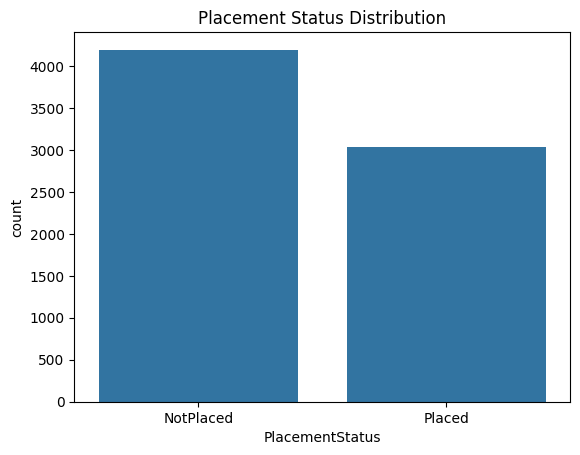

In [9]:
#Visualize placement outcomes:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="PlacementStatus")
plt.title("Placement Status Distribution")
plt.show()

- Pandas → helps us read and analyze data in table format.
- Matplotlib → helps us create graphs.
- Seaborn → helps us create attractive statistical graphs with less code.

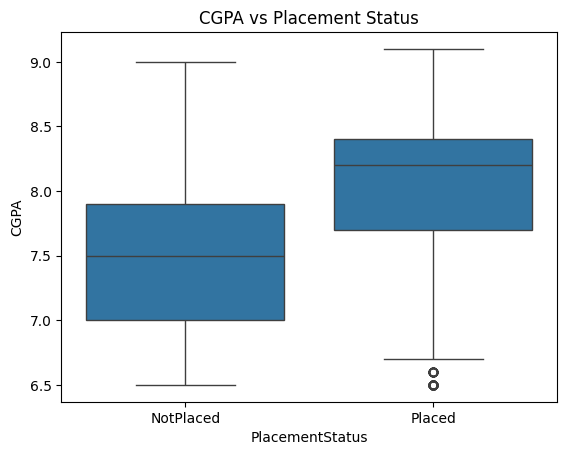

In [10]:
sns.boxplot(data=df, x="PlacementStatus", y="CGPA")
plt.title("CGPA vs Placement Status")
plt.show()

Ananlyze the graph:
1. The median CGPA of placed students (~8.1) is higher than that of not-placed students (~7.5).
2. Placed students generally have higher CGPAs than not-placed students.
3. The middle 50% of placed students have CGPAs around 7.6–8.4, while not-placed students have around 7.0–7.9.
4. The CGPA ranges overlap(see boxes of both are in same range 7.0 to 7.9 in unplaced and 7.6 to 8.4 in unplaced), indicating that some students with similar CGPAs have different placement outcomes.
5. Conclusion: CGPA appears to be positively associated with placement, but it alone cannot determine placement status. Other factors such as aptitude, internships, and communication skills may also influence placement.

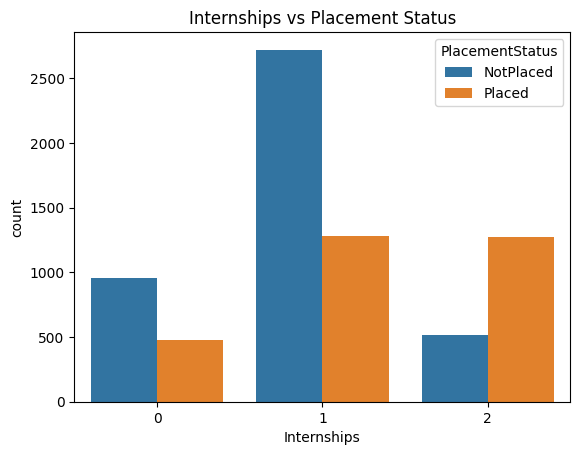

In [11]:
#Step 1 — Internships vs Placement
sns.countplot(data=df, x="Internships", hue="PlacementStatus")

plt.title("Internships vs Placement Status")
plt.show()

Observations
1. 0 internships: The number of not-placed students (~950) is higher than placed students (~480).
2. 1 internship: Not-placed students (~2,700) are more than placed students (~1,300).
3. 2 internships: Placed students (~1,280) are significantly more than not-placed students (~500).
4. Students with two internships show a stronger placement outcome compared with students having zero or one internship.
5. Conclusion: Internship experience appears to be positively associated with placement status in this dataset.
Important: This graph shows student counts, not placement percentages. To compare placement chances more accurately, we should calculate the placement rate for each internship category.

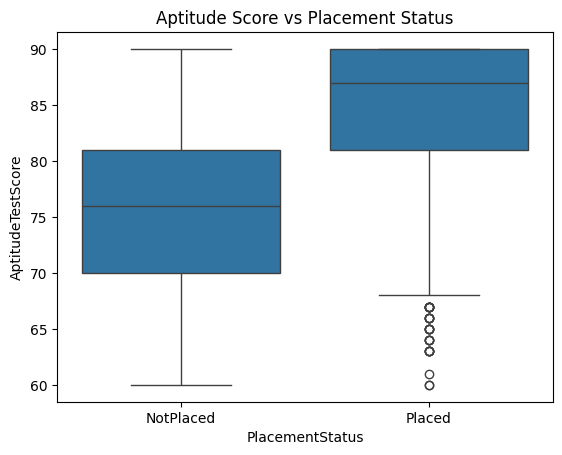

In [12]:
#Step 2 — Aptitude score vs Placement
sns.boxplot(data=df, x="PlacementStatus", y="AptitudeTestScore")

plt.title("Aptitude Score vs Placement Status")
plt.show()

Observations for your notes
1. The median aptitude score of placed students (~88) is higher than that of not-placed students (~76).
2. The middle 50% of placed students have scores around 82–91, while not-placed students have scores around 70–82.
3. Placed students generally have higher aptitude scores than not-placed students.
4. The two groups show some overlap, indicating that aptitude score alone cannot determine placement.
5. Some placed students have unusually low aptitude scores, represented by outliers.
6. Conclusion: Aptitude test score appears to be positively associated with placement status and may be an important feature for our ML model.

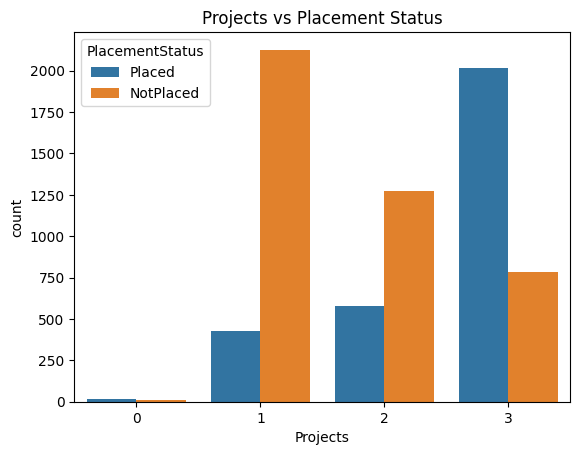

In [13]:
#Step 3 — Projects vs Placement
sns.countplot(data=df, x="Projects", hue="PlacementStatus")

plt.title("Projects vs Placement Status")
plt.show()

Observations:
* Students completing 3 projects show a stronger placement outcome compared with students completing fewer projects.
* Conclusion: The number of projects appears to be positively associated with placement status.

In [14]:
#Step 1: Check placement percentages
df["PlacementStatus"].value_counts(normalize=True)*100

PlacementStatus
NotPlaced    58.034602
Placed       41.965398
Name: proportion, dtype: float64

In [15]:
#Step 2: Check categorical columns
df.select_dtypes(include="object").nunique()

ExtracurricularActivities    2
PlacementTraining            2
PlacementStatus              2
dtype: int64

This shows how many unique categories are present in each text column.

In [16]:
df.select_dtypes(include="object").head()

,ExtracurricularActivities,PlacementTraining,PlacementStatus
0,No,No,NotPlaced
1,Yes,Yes,NotPlaced
2,No,No,NotPlaced
3,Yes,Yes,Placed
4,No,No,NotPlaced


In [17]:
#Step 3: Separate input features(x) and target(y)
X = df.drop("PlacementStatus", axis=1)
y = df["PlacementStatus"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7225, 10)
Target shape: (7225,)


X contains the 10 input features.
y contains the placement outcome we want to predict.

In [18]:
# Convert categorical columns into numerical values
X = X.copy()

X["ExtracurricularActivities"] = X["ExtracurricularActivities"].map({
    "Yes": 1,
    "No": 0
})

X["PlacementTraining"] = X["PlacementTraining"].map({
    "Yes": 1,
    "No": 0
})

# Check the result
X.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks
0,7.7,1,1,0,69,4.0,0,0,55,69
1,7.6,2,3,1,80,4.3,1,1,57,70
2,7.0,1,1,1,64,4.1,0,0,58,62
3,7.9,1,3,2,90,4.8,1,1,82,80
4,6.7,0,2,1,71,3.7,0,0,55,67


In [19]:
y.head() #remain unchnaged placed/unplaced

0    NotPlaced
1    NotPlaced
2    NotPlaced
3       Placed
4    NotPlaced
Name: PlacementStatus, dtype: object

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5780, 10)
X_test: (1445, 10)
y_train: (5780,)
y_test: (1445,)


* test_size=0.2 → 20% data testing ke liye.
* random_state=42 → har baar same split milega.
* stratify=y → Placed aur NotPlaced ka proportion train aur test dono mein similar rahega.

In [21]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model using training data
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


* LogisticRegression() creates our classification model.
* max_iter=1000 allows enough iterations for the model to learn.
* model.fit() trains the model using input features (X_train) and actual placement labels (y_train).

In [22]:
# Step 1 : Predict placement for test students
y_pred = model.predict(X_test)

# Display first 10 predictions
print(y_pred[:10])

['NotPlaced' 'NotPlaced' 'NotPlaced' 'Placed' 'Placed' 'NotPlaced'
 'NotPlaced' 'NotPlaced' 'NotPlaced' 'NotPlaced']


In [23]:
#Step 2: Compare actual vs predicted
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
1034,Placed,NotPlaced
2184,NotPlaced,NotPlaced
1956,NotPlaced,NotPlaced
6039,Placed,Placed
5324,Placed,Placed
5059,NotPlaced,NotPlaced
5882,NotPlaced,NotPlaced
2766,NotPlaced,NotPlaced
2394,NotPlaced,NotPlaced
4307,NotPlaced,NotPlaced


In [24]:
#Step 3: Evaluate model accuracy
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 79.65397923875432 %


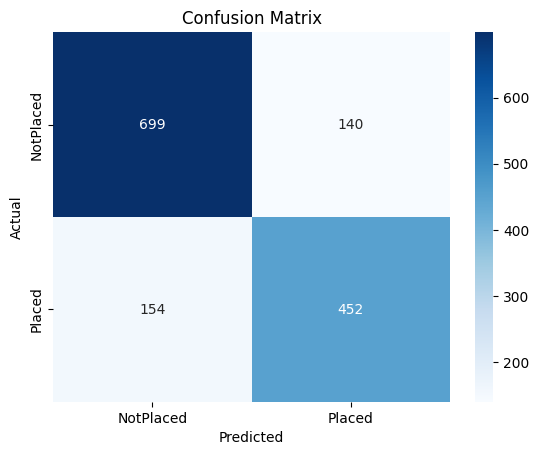

              precision    recall  f1-score   support

   NotPlaced       0.82      0.83      0.83       839
      Placed       0.76      0.75      0.75       606

    accuracy                           0.80      1445
   macro avg       0.79      0.79      0.79      1445
weighted avg       0.80      0.80      0.80      1445



In [25]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["NotPlaced", "Placed"])

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["NotPlaced", "Placed"],
            yticklabels=["NotPlaced", "Placed"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Detailed evaluation
print(classification_report(y_test, y_pred))

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create and train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

# Check accuracy
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred) * 100)

Decision Tree Accuracy: 70.17301038062284


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate accuracy
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred) * 100)

Random Forest Accuracy: 78.75432525951557


In [28]:
#Compare all models properly
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred))

print("DECISION TREE")
print(classification_report(y_test, dt_pred))

print("RANDOM FOREST")
print(classification_report(y_test, rf_pred))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

   NotPlaced       0.82      0.83      0.83       839
      Placed       0.76      0.75      0.75       606

    accuracy                           0.80      1445
   macro avg       0.79      0.79      0.79      1445
weighted avg       0.80      0.80      0.80      1445

DECISION TREE
              precision    recall  f1-score   support

   NotPlaced       0.74      0.74      0.74       839
      Placed       0.64      0.65      0.65       606

    accuracy                           0.70      1445
   macro avg       0.69      0.69      0.69      1445
weighted avg       0.70      0.70      0.70      1445

RANDOM FOREST
              precision    recall  f1-score   support

   NotPlaced       0.80      0.85      0.82       839
      Placed       0.77      0.71      0.74       606

    accuracy                           0.79      1445
   macro avg       0.78      0.78      0.78      1445
weighted avg       0.79   

In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Different settings ko test karenge
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10]
}

# Best parameters find karna
grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Best model
best_rf = grid.best_estimator_

# Test data par prediction
rf_pred = best_rf.predict(X_test)

print("Best Parameters:", grid.best_params_)
print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred) * 100)

Best Parameters: {'max_depth': 5, 'min_samples_split': 10, 'n_estimators': 100}
Tuned Random Forest Accuracy: 79.03114186851211


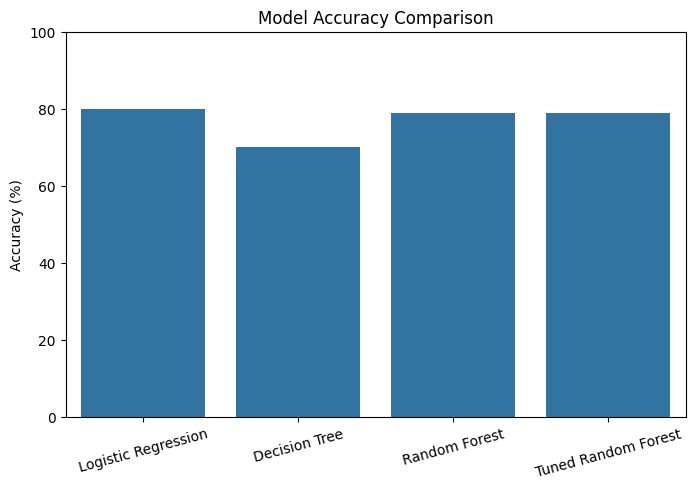

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

models = ["Logistic Regression", "Decision Tree",
          "Random Forest", "Tuned Random Forest"]

accuracies = [80, 70, 79, 79]

plt.figure(figsize=(8, 5))

sns.barplot(x=models, y=accuracies)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.show()

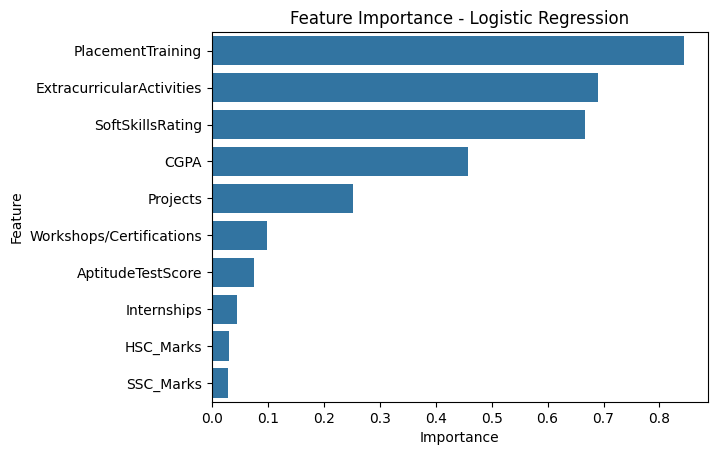

In [31]:
# Feature importance using Logistic Regression coefficients

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": abs(model.coef_[0])
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Feature Importance - Logistic Regression")
plt.show()

Conclusion: Placement training, extracurricular activities, soft skills and CGPA are the most influential features according to this graph.
Note: This graph uses absolute Logistic Regression coefficients, so it shows the magnitude of influence, not whether a feature increases or decreases placement probability. Since the features have different scales, coefficient magnitudes should ideally be compared after standardizing the features.

In [32]:
import joblib

# Save the trained model
joblib.dump(model, "placement_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [33]:
# Load the saved model
import joblib

loaded_model = joblib.load("placement_model.pkl")

# Sample student data (10 input features)
new_student = pd.DataFrame([{
    "CGPA": 8.5,
    "Internships": 1,
    "Projects": 2,
    "Workshops/Certifications": 2,
    "AptitudeTestScore": 85,
    "SoftSkillsRating": 4.5,
    "ExtracurricularActivities": 1,
    "PlacementTraining": 1,
    "SSC_Marks": 85,
    "HSC_Marks": 88
}])

# Predict placement
prediction = loaded_model.predict(new_student)

if prediction[0] == "Placed":
    print("Student is likely to be PLACED")
else:
    print("Student is likely to be NOT PLACED")

Student is likely to be PLACED


In [34]:
!pip install streamlit

In [35]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [36]:
import ipywidgets as widgets
from IPython.display import display
import pandas as pd
import joblib

# Load saved model
model = joblib.load("placement_model.pkl")

# Input fields
cgpa = widgets.FloatSlider(description="CGPA", min=0, max=10, value=8)
internships = widgets.IntSlider(description="Internships", min=0, max=5)
projects = widgets.IntSlider(description="Projects", min=0, max=5)
workshops = widgets.IntSlider(description="Workshops", min=0, max=5)
aptitude = widgets.IntSlider(description="Aptitude", min=0, max=100, value=75)
softskills = widgets.FloatSlider(description="Soft Skills", min=0, max=5, value=4)
extra = widgets.Dropdown(description="Activities", options=["No", "Yes"])
training = widgets.Dropdown(description="Training", options=["No", "Yes"])
ssc = widgets.IntSlider(description="SSC Marks", min=0, max=100, value=80)
hsc = widgets.IntSlider(description="HSC Marks", min=0, max=100, value=80)

button = widgets.Button(description="Predict Placement", button_style="success")
output = widgets.Output()

def predict_placement(b):
    with output:
        output.clear_output()

        student = pd.DataFrame([{
            "CGPA": cgpa.value,
            "Internships": internships.value,
            "Projects": projects.value,
            "Workshops/Certifications": workshops.value,
            "AptitudeTestScore": aptitude.value,
            "SoftSkillsRating": softskills.value,
            "ExtracurricularActivities": 1 if extra.value == "Yes" else 0,
            "PlacementTraining": 1 if training.value == "Yes" else 0,
            "SSC_Marks": ssc.value,
            "HSC_Marks": hsc.value
        }])

        prediction = model.predict(student)[0]

        if prediction == "Placed":
            print("🎉 Student is likely to be PLACED!")
        else:
            print("Student is likely to be NOT PLACED.")

button.on_click(predict_placement)

display(widgets.VBox([
    cgpa, internships, projects, workshops,
    aptitude, softskills, extra, training,
    ssc, hsc, button, output
]))

In [44]:

import ipywidgets as widgets
from IPython.display import display
import pandas as pd
import joblib

# Load saved model
model = joblib.load("placement_model.pkl")

# Input fields
cgpa = widgets.FloatSlider(description="CGPA", min=0, max=10, value=8)
internships = widgets.IntSlider(description="Internships", min=0, max=5)
projects = widgets.IntSlider(description="Projects", min=0, max=5)
workshops = widgets.IntSlider(description="Workshops", min=0, max=5)
aptitude = widgets.IntSlider(description="Aptitude", min=0, max=100, value=75)
softskills = widgets.FloatSlider(description="Soft Skills", min=0, max=5, value=4)
extra = widgets.Dropdown(description="Activities", options=["No", "Yes"])
training = widgets.Dropdown(description="Training", options=["No", "Yes"])
ssc = widgets.IntSlider(description="SSC Marks", min=0, max=100, value=80)
hsc = widgets.IntSlider(description="HSC Marks", min=0, max=100, value=80)

button = widgets.Button(
    description="Predict Placement",
    button_style="success"
)

output = widgets.Output()

def predict_placement(b):
    with output:
        output.clear_output(wait=True)

        try:
            student = pd.DataFrame([{
                "CGPA": cgpa.value,
                "Internships": internships.value,
                "Projects": projects.value,
                "Workshops/Certifications": workshops.value,
                "AptitudeTestScore": aptitude.value,
                "SoftSkillsRating": softskills.value,
                "ExtracurricularActivities": 1 if extra.value == "Yes" else 0,
                "PlacementTraining": 1 if training.value == "Yes" else 0,
                "SSC_Marks": ssc.value,
                "HSC_Marks": hsc.value
            }])

            prediction = model.predict(student)[0]

            if prediction == "Placed":
                print("🎉 Student is likely to be PLACED!")
            else:
                print("Student is likely to be NOT PLACED.")

        except Exception as e:
            print("Error:", e)

button.on_click(predict_placement)

display(widgets.VBox([
    cgpa, internships, projects, workshops,
    aptitude, softskills, extra, training,
    ssc, hsc, button, output
]))
